# Fő elemzés 2. rész: modellezés, statisztikai összehasonlítás, jellemzőfontosság

A `results/elemzes/` mappa tartalmát dolgozza fel, amelyet a `python -m src.elemzes.run_analysis` állít elő (5-szörös K-Fold, 5 ismétlés = 25 kör modellenként).

In [14]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

R = Path("../results/elemzes")
VAR = {"g1g2_nelkul": "G1/G2 nélkül", "g1g2_vel": "G1/G2-vel"}
MOD = {"dummy": "Átlagjósló", "baseline": "Baseline (Ridge)", "advanced": "Haladó (GB)"}
pd.set_option("display.width", 200)

def show(name):
    if (R / name).exists():
        display(Image(filename=R / name, width=800))
    else:
        print("Hiányzik:", name, "(a SHAP-hoz kell a shap csomag)")

## A kísérlet: a feature engineering és a dimenziócsökkentés hatása

Rögzített hiperparaméterekkel, azonos CV-felosztásokon. Az RMSE az 25 kör átlaga, kisebb a jobb. A dimenziócsökkentés a főelemzéshez a PCA nélküli (nincs / 20 legjobb jellemző) lehetőségek közül az átlagosan jobbat kapja.

In [2]:
exp = pd.read_csv(R / "reduction_experiment.csv")
exp["variant"] = exp["variant"].map(VAR)
exp["model"] = exp["model"].map(MOD)
exp.pivot_table(index=["variant", "feature_engineering", "reduction"], columns="model", values="rmse").round(3)

model                                       Baseline (Ridge)  Haladó (GB)
variant      feature_engineering reduction                               
G1/G2 nélkül False               kbest                 2.744        2.744
                                 none                  2.750        2.764
                                 pca                   2.785        2.876
             True                kbest                 2.742        2.805
                                 none                  2.747        2.753
                                 pca                   2.765        2.908
G1/G2-vel    False               kbest                 1.261        1.356
                                 none                  1.296        1.307
                                 pca                   1.364        1.662
             True                kbest                 1.260        1.385
                                 none                  1.297        1.329
                                 pca                   1.271        1.551

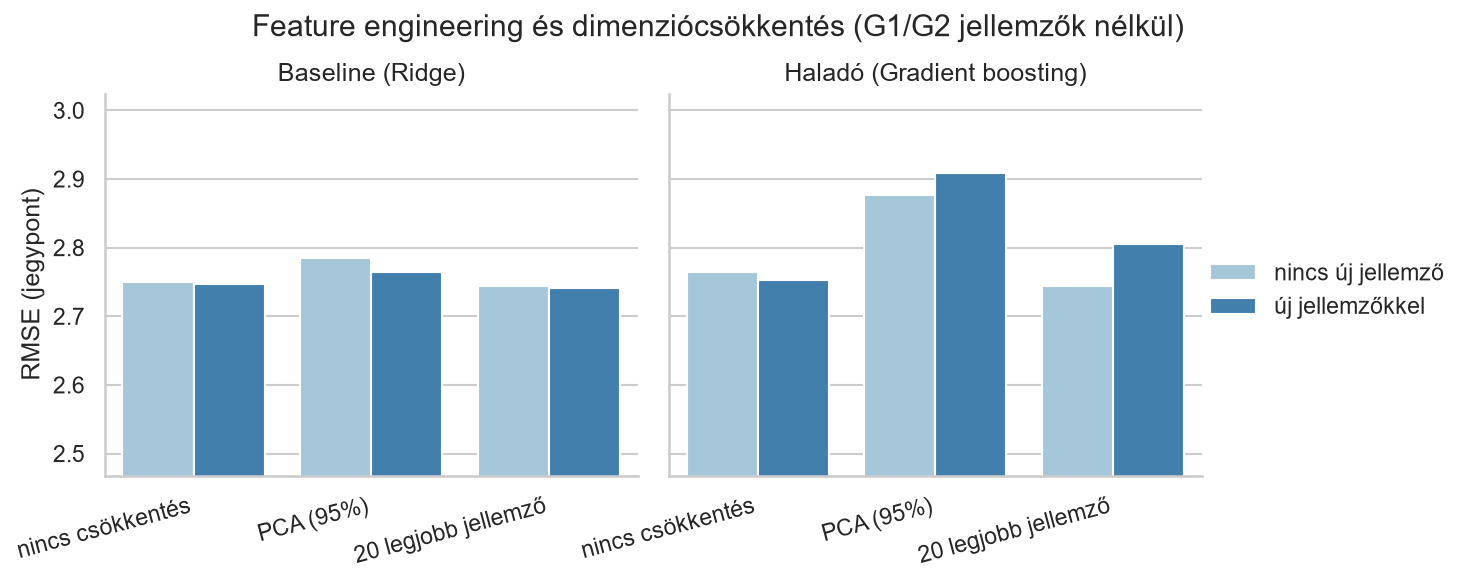

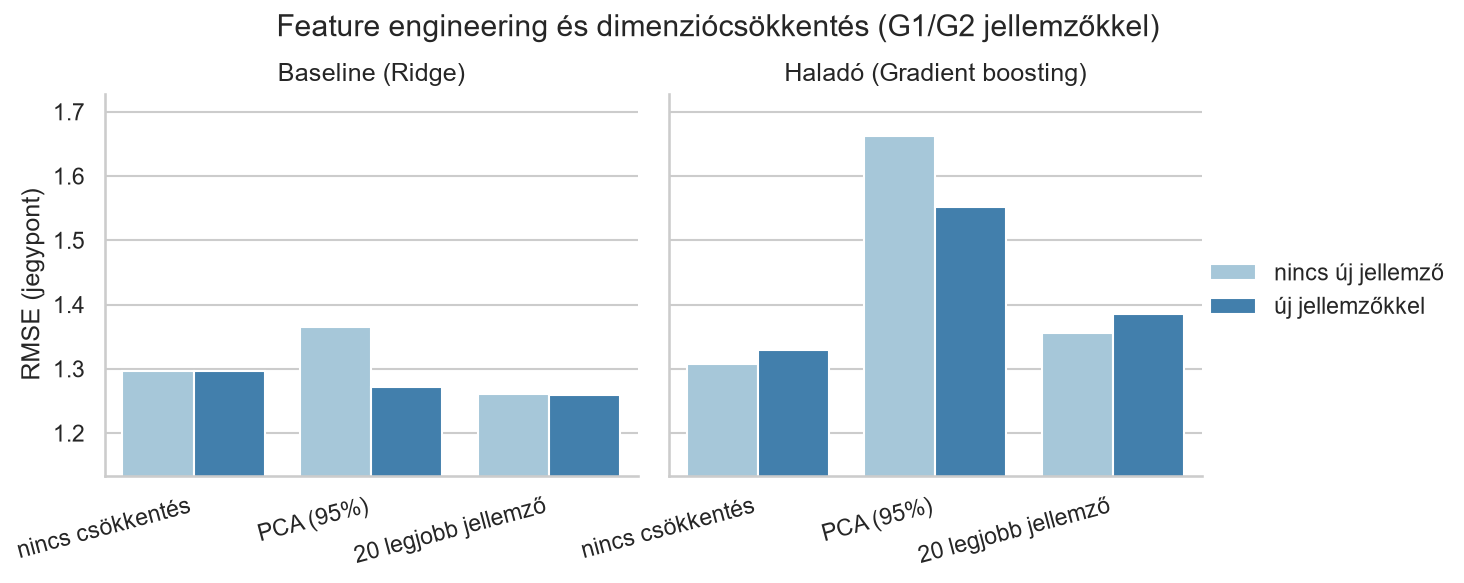

In [3]:
show("dimenziocsokkentes_g1g2_nelkul.png")
show("dimenziocsokkentes_g1g2_vel.png")

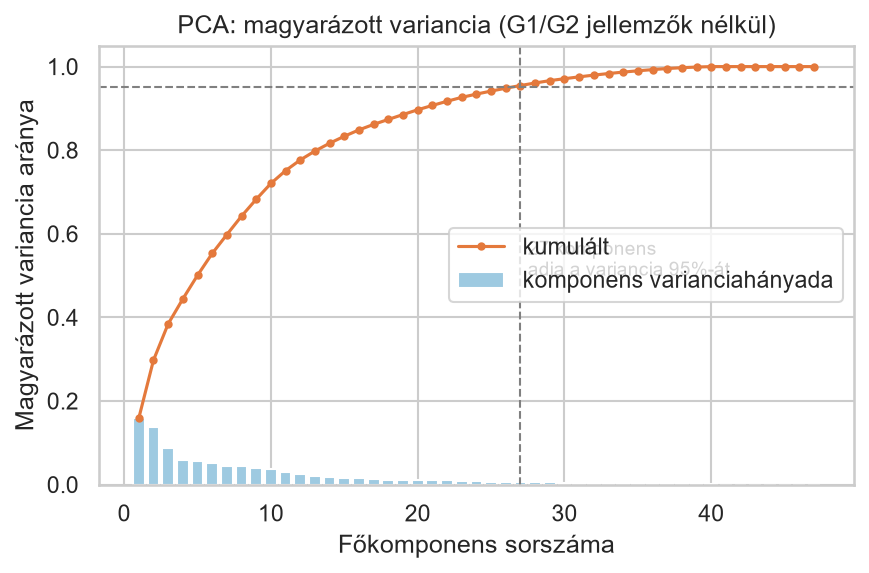

In [4]:
show("pca_variancia_g1g2_nelkul.png")

## Modellezés és keresztvalidáció

- külső: ismételt 5-szörös K-Fold (5 ismétlés), minden modell ugyanazokat a felosztásokat kapja
- belső: 3-szoros CV hiperparaméter-hangoláshoz (beágyazott keresztvalidáció), így a teszthalmaz nem szól bele a hangolásba
- az egész lánc (jellemzők, outliervágás, imputálás, skálázás, kódolás, csökkentés, modell) a CV minden körében csak a tanítóhalmazból tanul
- átlagjósló (mindig a tanítóhalmaz átlagát adja): alsó referencia
- baseline: Ridge-regresszió, haladó modell: gradient boosting

In [5]:
s = pd.read_csv(R / "summary.csv")
def fmt(r, m, d=3):
    return f"{r[m]:.{d}f} [{r[m + '_ci_also']:.{d}f}; {r[m + '_ci_felso']:.{d}f}]"
tab = pd.DataFrame({
    "változat": s["variant"].map(VAR), "modell": s["model"].map(MOD),
    "RMSE [95% CI]": s.apply(lambda r: fmt(r, "rmse"), axis=1),
    "MAE [95% CI]": s.apply(lambda r: fmt(r, "mae"), axis=1),
    "R² [95% CI]": s.apply(lambda r: fmt(r, "r2"), axis=1),
})
tab

,változat,modell,RMSE [95% CI],MAE [95% CI],R² [95% CI]
0,G1/G2 nélkül,Átlagjósló,3.211 [2.391; 4.032],2.410 [1.921; 2.900],-0.013 [-0.039; 0.012]
1,G1/G2 nélkül,Baseline (Ridge),2.727 [2.083; 3.371],1.996 [1.678; 2.313],0.265 [0.135; 0.394]
2,G1/G2 nélkül,Haladó (GB),2.700 [1.984; 3.415],1.990 [1.726; 2.255],0.283 [0.164; 0.401]
3,G1/G2-vel,Átlagjósló,3.211 [2.391; 4.032],2.410 [1.921; 2.900],-0.013 [-0.039; 0.012]
4,G1/G2-vel,Baseline (Ridge),1.284 [0.695; 1.873],0.829 [0.606; 1.052],0.839 [0.767; 0.911]
5,G1/G2-vel,Haladó (GB),1.248 [0.658; 1.838],0.798 [0.558; 1.038],0.848 [0.772; 0.924]


A konfidenciaintervallumok a Nadeau–Bengio-féle korrigált szórással készültek: az ismételt K-Fold körei nem függetlenek (a tanítóhalmazok átfednek), ezért a sima szórás túl szűk intervallumot adna. Az intervallumok szélesek, mert a körök közti ingadozás nagy, ezt a modellek összehasonlításánál a páros próba kezeli.

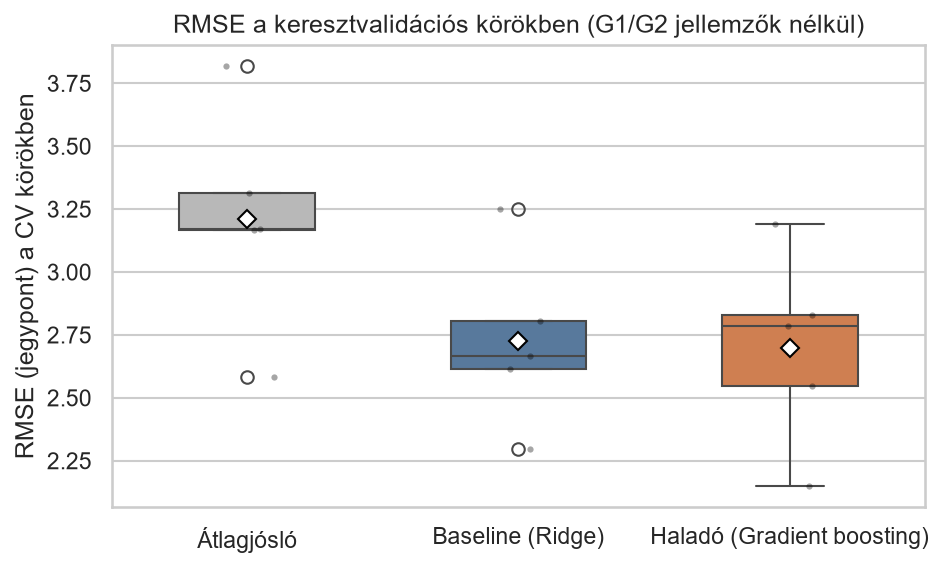

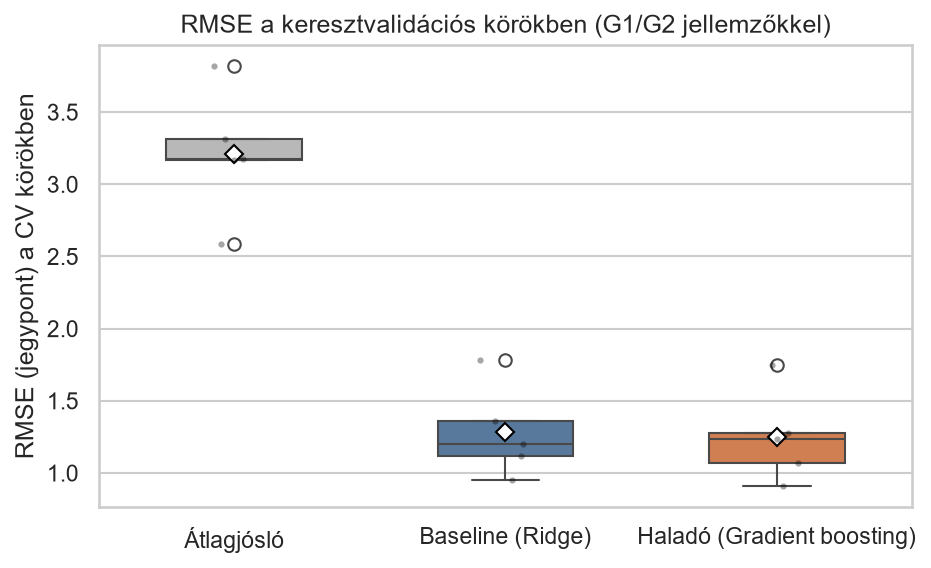

In [6]:
show("cv_rmse_g1g2_nelkul.png")
show("cv_rmse_g1g2_vel.png")

## A baseline és a haladó modell statisztikai összehasonlítása

A különbség: RMSE(baseline) − RMSE(haladó), pozitív érték = a haladó modell jobb. Elsődleges próba a korrigált páros t-próba, kiegészítésként a Wilcoxon-féle előjeles rangpróba (ennek p-értéke a körök függősége miatt optimista lehet).

In [7]:
c = pd.read_csv(R / "comparison.csv")
c["változat"] = c["variant"].map(VAR)
c["különbség [95% CI]"] = c.apply(lambda r: f"{r['rmse_kulonbseg']:.3f} [{r['ci_also']:.3f}; {r['ci_felso']:.3f}]", axis=1)
c[["változat", "metrika", "különbség [95% CI]", "t", "p_korrigalt_t", "p_wilcoxon", "hatasmeret_dz", "a_halado_jobb_koroket_%"]].round(4)

,változat,metrika,különbség [95% CI],t,p_korrigalt_t,p_wilcoxon,hatasmeret_dz,a_halado_jobb_koroket_%
0,G1/G2 nélkül,rmse,0.027 [-0.161; 0.216],0.4026,0.7078,0.6250,0.2701,60.0
1,G1/G2 nélkül,mae,0.005 [-0.107; 0.118],0.1333,0.9004,1.0000,0.0894,40.0
2,G1/G2-vel,rmse,0.036 [-0.099; 0.171],0.7452,0.4975,0.4375,0.4999,80.0
3,G1/G2-vel,mae,0.031 [-0.058; 0.119],0.9611,0.3909,0.3125,0.6447,60.0


**Az eredmény értelmezése (a jelenlegi, rögzített seedű futásra).** Egyik változatban és egyik mutatónál sem találunk szignifikáns különbséget a baseline és a haladó modell között a korrigált t-próbával (p > 0,05, a konfidenciaintervallum átfogja a nullát). A Wilcoxon-próba néhány esetben p < 0,05-öt ad, de az a körök függősége miatt optimista, és a két mutató (RMSE, MAE) ellentmondó előjelű különbséget mutat, ezért nem tekintjük bizonyítéknak. Magyarán: ezen az adathalmazon a haladó modell nem bizonyíthatóan jobb az egyszerű lineáris baseline-nál. Ez hihető: a kapcsolatok jórészt lineárisak, és kevés az adat (649 sor) a bonyolultabb modell előnyének kihasználásához.

In [8]:
bp = pd.read_csv(R / "best_params.csv")
bp["variant"] = bp["variant"].map(VAR)
bp.groupby(["variant", "model", "params"]).size().rename("körök száma").reset_index()

,variant,model,params,körök száma
0,G1/G2 nélkül,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",1
1,G1/G2 nélkül,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",3
2,G1/G2 nélkül,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",1
3,G1/G2 nélkül,baseline,"{""model__alpha"": 100}",2
4,G1/G2 nélkül,baseline,"{""model__alpha"": 10}",3
5,G1/G2-vel,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",2
6,G1/G2-vel,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",2
7,G1/G2-vel,advanced,"{""model__learning_rate"": 0.03, ""model__max_dep...",1
8,G1/G2-vel,baseline,"{""model__alpha"": 10}",5


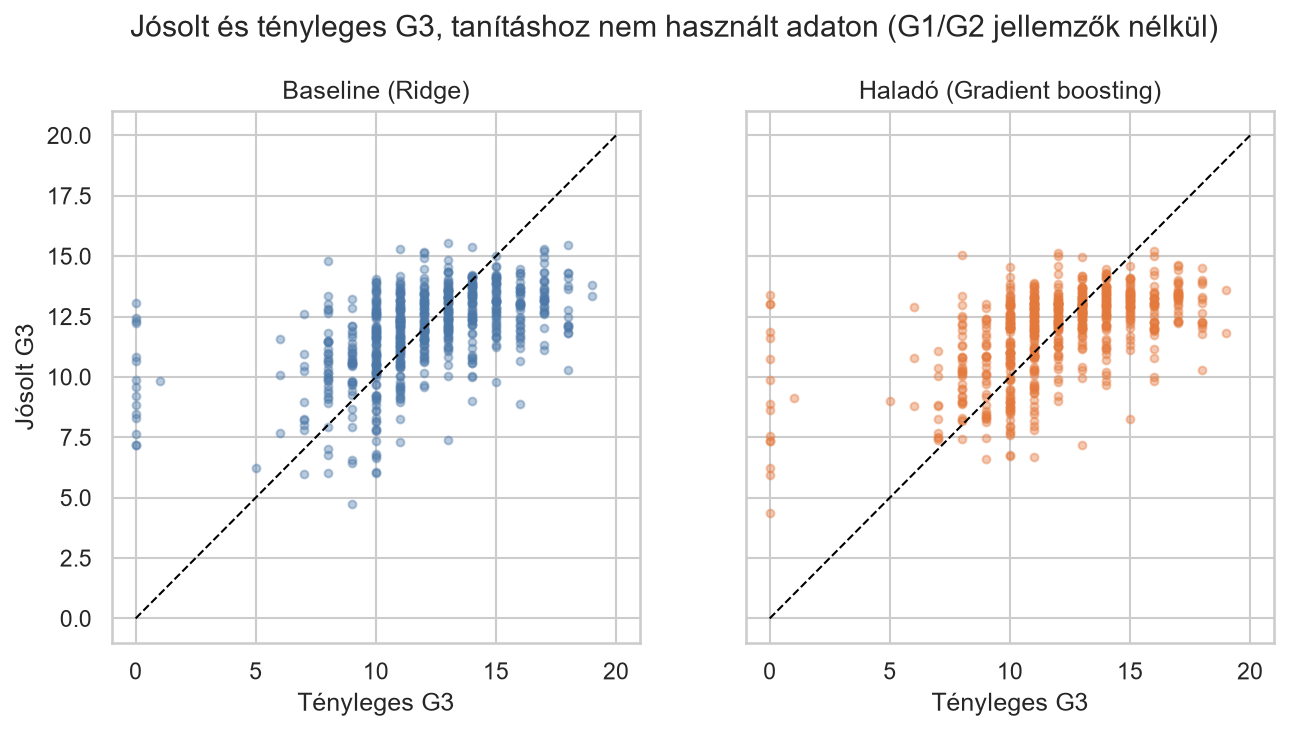

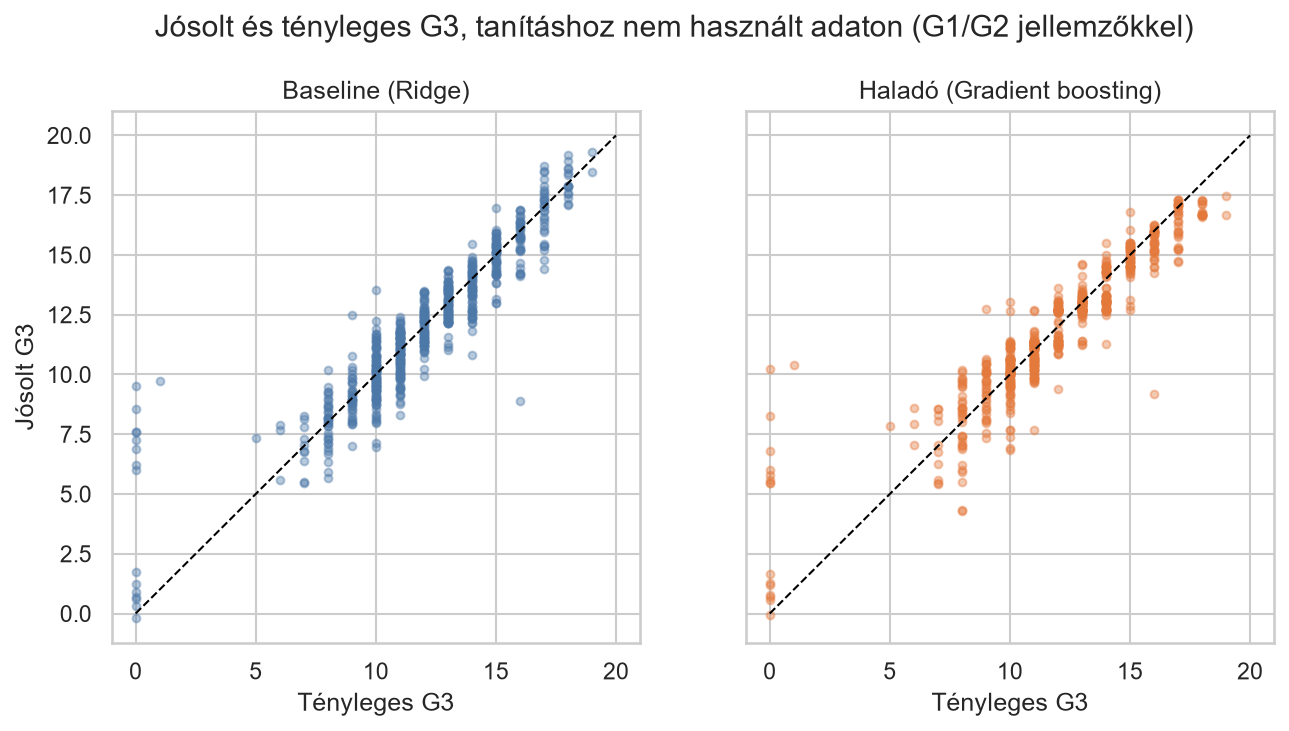

In [9]:
show("josolt_vs_tenyleges_g1g2_nelkul.png")
show("josolt_vs_tenyleges_g1g2_vel.png")

## Jellemzőfontosság

**Csoportos permutációs fontosság.** A tanításhoz nem használt (teszt) adaton egy jellemzőcsoport értékeit megkeverjük, és az RMSE növekedését mérjük. A korreláló jellemzők (pl. `Dalc` és `Walc`) egy csoportban vannak, mert külön-külön megkeverve a fontosságuk szétoszlana, és alulbecsülnénk őket. Az átlag és a szórás a 25 CV körre vonatkozik.

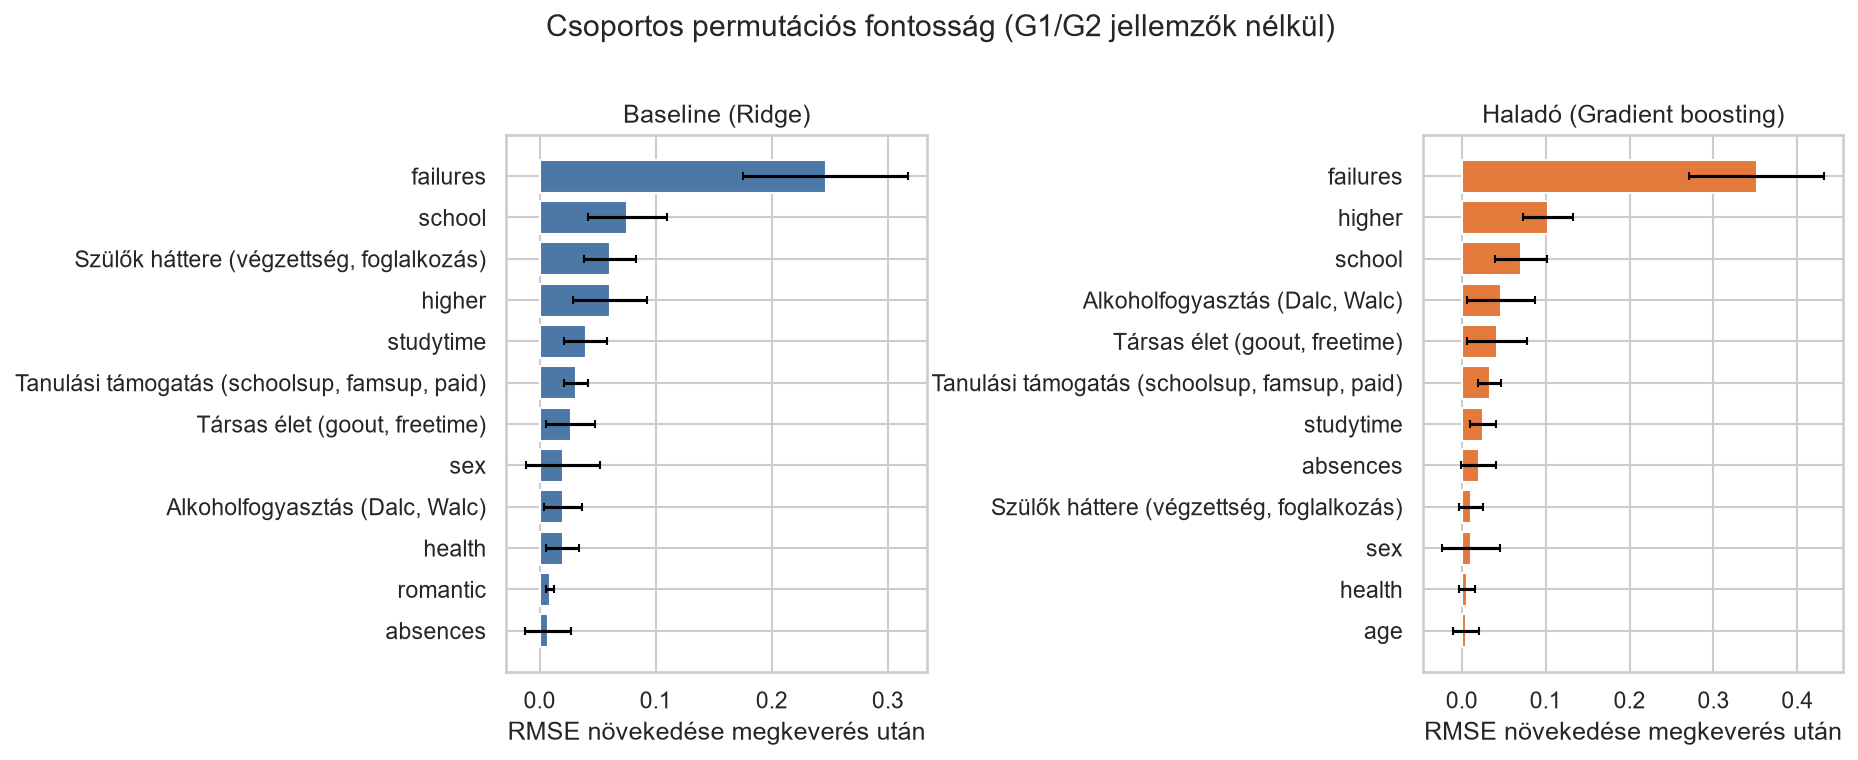

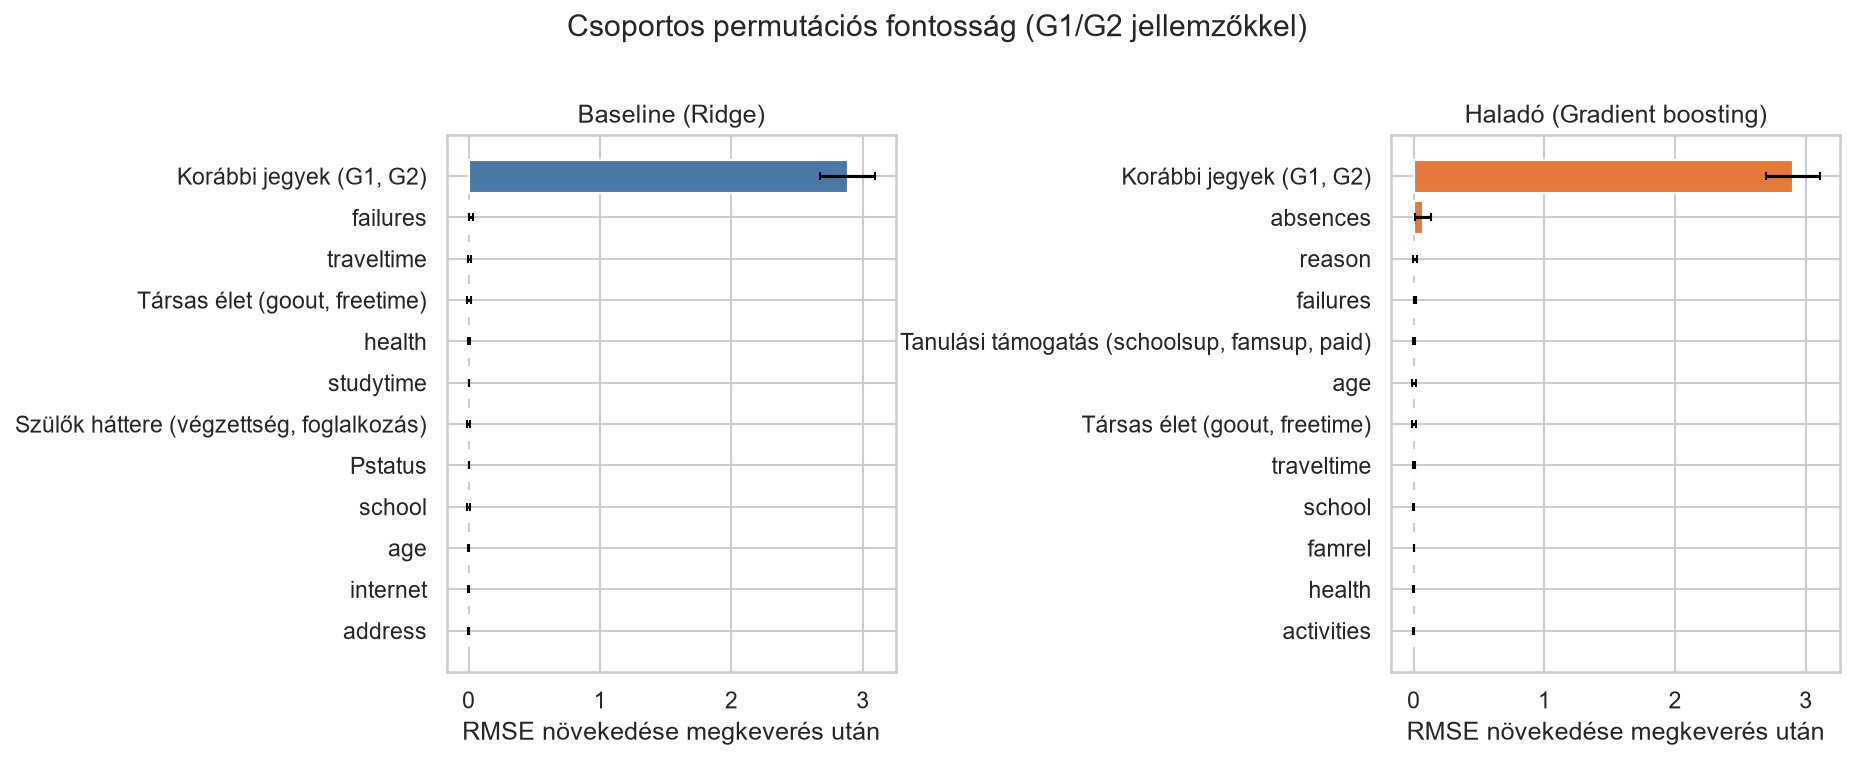

In [10]:
show("permutacios_fontossag_g1g2_nelkul.png")
show("permutacios_fontossag_g1g2_vel.png")

In [11]:
p = pd.read_csv(R / "permutation_importance.csv")
p["model"] = p["model"].map(MOD)
for (v, m), d in p.groupby(["variant", "model"]):
    print(VAR[v], "|", m)
    print(d.nlargest(8, "atlag")[["csoport", "atlag", "szoras"]].round(3).to_string(index=False), "\n")

G1/G2 nélkül | Baseline (Ridge)
                                     csoport  atlag  szoras
                                    failures  0.246   0.071
                                      school  0.076   0.034
    Szülők háttere (végzettség, foglalkozás)  0.061   0.023
                                      higher  0.060   0.032
                                   studytime  0.040   0.019
Tanulási támogatás (schoolsup, famsup, paid)  0.031   0.011
               Társas élet (goout, freetime)  0.027   0.021
                                         sex  0.020   0.032 

G1/G2 nélkül | Haladó (GB)
                                     csoport  atlag  szoras
                                    failures  0.352   0.081
                                      higher  0.103   0.030
                                      school  0.071   0.031
              Alkoholfogyasztás (Dalc, Walc)  0.047   0.041
               Társas élet (goout, freetime)  0.042   0.036
Tanulási támogatás (schoolsup, famsup, 

**SHAP.** A végleges haladó modellen (a külső körökben leggyakrabban kiválasztott hiperparaméterekkel, a teljes adaton tanítva) számolt SHAP értékek megmutatják a hatás irányát is. Fontos különbség a permutációs fontossághoz képest: a SHAP a modell *tanítóadatán* értelmez, a permutációs fontosság a *tanításhoz nem használt* adaton mér.

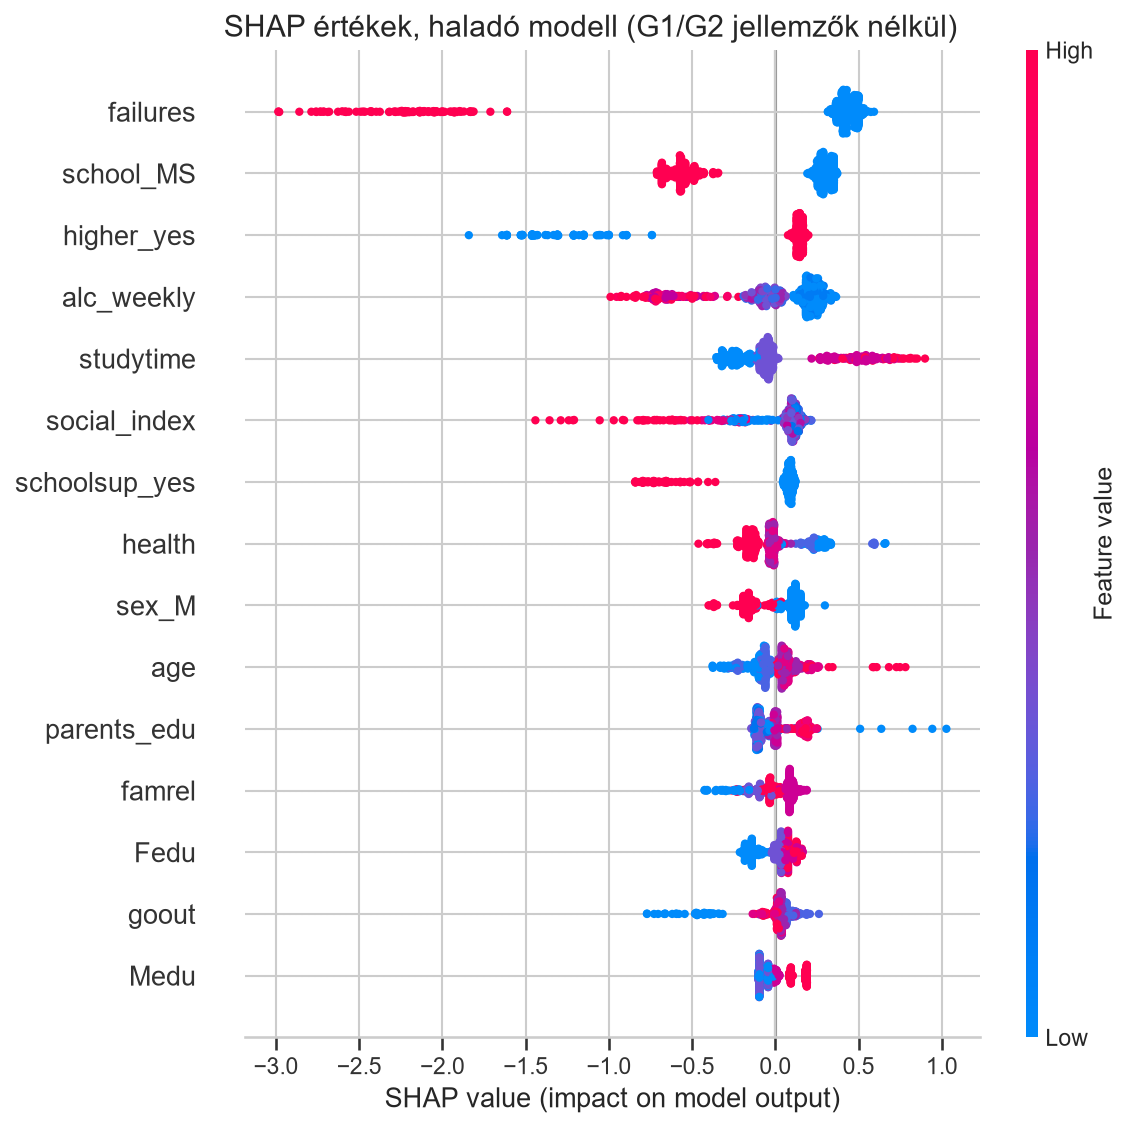

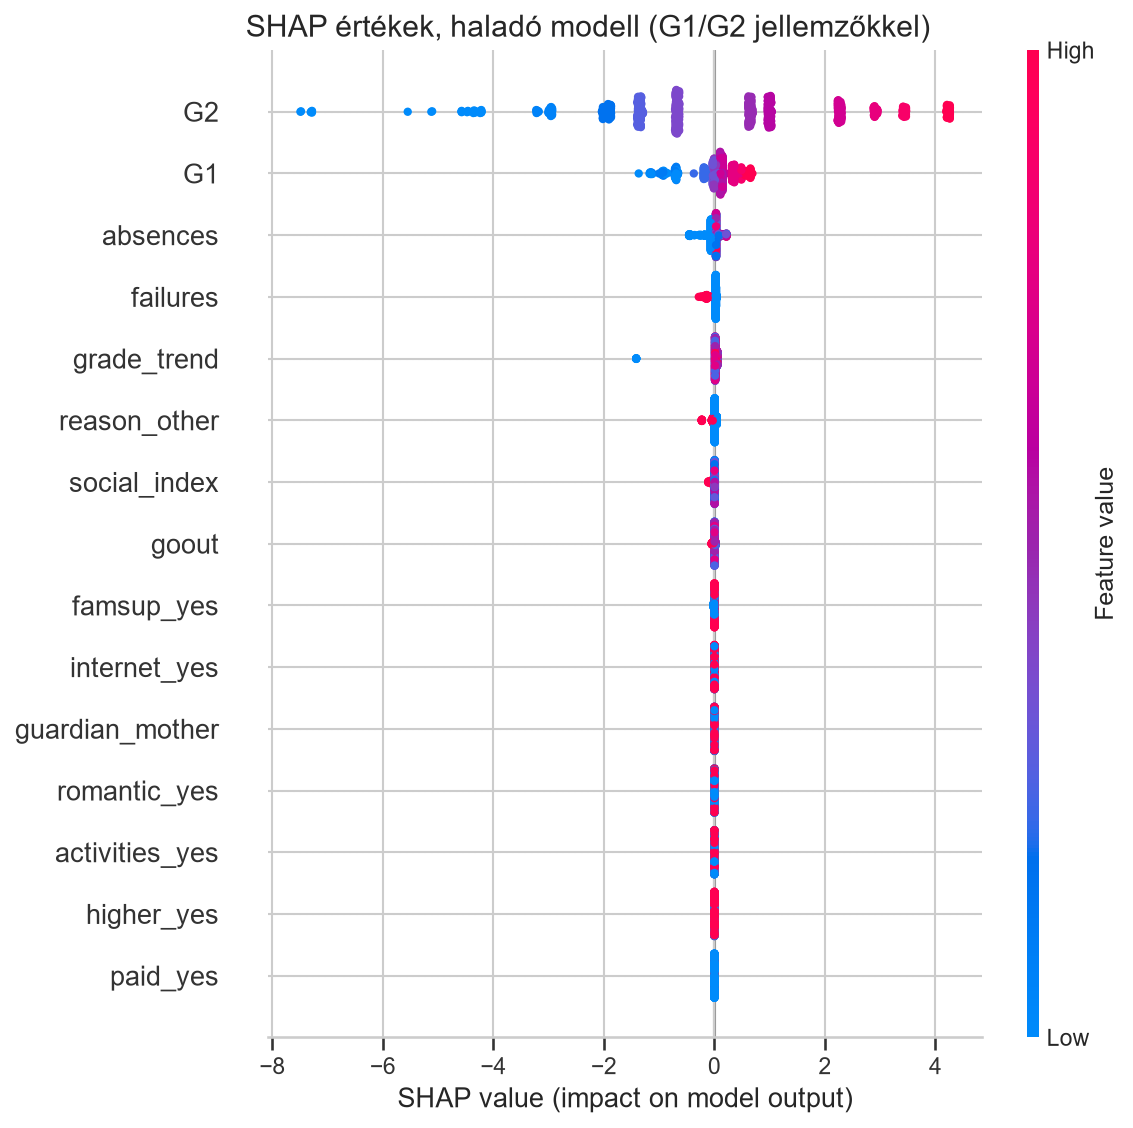

In [12]:
show("shap_meh_g1g2_nelkul.png")
show("shap_meh_g1g2_vel.png")

In [13]:
coef = pd.read_csv(R / "baseline_coefficients.csv")
for v, d in coef.groupby("variant"):
    print(VAR[v], ": a baseline (Ridge) legnagyobb standardizált együtthatói")
    print(d.head(10)[["jellemzo", "egyutthato"]].round(3).to_string(index=False), "\n")

G1/G2 nélkül : a baseline (Ridge) legnagyobb standardizált együtthatói
     jellemzo  egyutthato
   higher_yes       1.412
    school_MS      -1.073
 social_index      -0.940
     failures      -0.851
schoolsup_yes      -0.660
 Fjob_teacher       0.572
        sex_M      -0.563
        goout       0.517
Fjob_services      -0.427
  Mjob_health       0.426 

G1/G2-vel : a baseline (Ridge) legnagyobb standardizált együtthatói
    jellemzo  egyutthato
          G2       1.490
          G1       1.307
 grade_trend       0.509
social_index      -0.412
Fjob_at_home       0.278
       goout       0.233
reason_other      -0.190
  Mjob_other      -0.179
    freetime       0.173
  higher_yes       0.172 



## A jellemzőfontosság korlátai

- **Korreláló jellemzők.** Ha két jellemző hasonló információt hordoz, a permutációs fontosság félrevezethet (a modell a megkevert helyett a másikra támaszkodhat). A csoportosítás ezt a nyilvánvaló esetekre kezeli, a rejtettebb korrelációkra nem.
- **Nem okság.** A fontosság azt mutatja, mire támaszkodik a modell, nem azt, hogy a jellemző változtatása megváltoztatná a jegyet. Pl. a `failures` (korábbi bukások) a jegyek jelzője, nem oka.
- **Magyarázóerő.** G1/G2 nélkül a modellek is csak a G3 varianciájának kb. 26-28%-át magyarázzák (R²), ezért a fontossági sorrend bizonytalanabb, a szórások nagyok.
- **Eltérő módszerek, eltérő sorrend.** A permutációs fontosság (teszt adat), a SHAP (tanítóadat) és a Ridge együtthatói nem ugyanazt mérik, ezért kisebb eltérések a sorrendben természetesek.
- **A G1/G2 dominanciája.** Velük a modell döntéseinek nagy részét ez a két jellemző adja, a többi jellemző fontossága elenyésző.